# Portfolio Market Risk Engine: VaR, Backtesting & Stress Testing Project

**Implementation of the three core VaR methodologies used on trading desks, statistical backtesting, and scenario stress testing**

**Important Assumtion: As purpose of project is VaR and Market risk we assume a simple equity portfolio of 5 stocks $10mm **

**Contents**
1. Configuration & Data
2. VaR & Expected Shortfall (Historical, Parametric, Monte Carlo)
3. Backtesting (Kupiec, Basel traffic-light zones)
4. Stress Testing (scenario shocks + correlation breakdown)

prices are simulated using a correlated, fat-tailed (Student-t) return process calibrated to realistic volatility/correlation assumptions for AAPL, MSFT, JPM, XOM, and AMZN — not pulled from a real feed. Student-t (not Normal) innovations are used deliberately because real equity returns are fat-tailed; a Normal-only simulation would itself understate tail risk.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
np.set_printoptions(suppress=True)

## 1. Configuration & Data 

In [2]:
# ---- Portfolio ----
TICKERS = ["AAPL", "MSFT", "JPM", "XOM", "AMZN"]
WEIGHTS = {"AAPL": 0.25, "MSFT": 0.25, "JPM": 0.20, "XOM": 0.15, "AMZN": 0.15}
PORTFOLIO_VALUE = 10_000_000.0

# ---- assumptions ----
N_DAYS = 756          # ~3 years of trading days
SEED = 42
ANNUAL_VOL = {"AAPL": 0.28, "MSFT": 0.26, "JPM": 0.24, "XOM": 0.30, "AMZN": 0.34}
ANNUAL_DRIFT = {"AAPL": 0.12, "MSFT": 0.14, "JPM": 0.09, "XOM": 0.06, "AMZN": 0.10}
T_DOF = 5              # Student-t degrees of freedom 
TRADING_DAYS = 252

# Approximate correlations assumptions
CORR_MATRIX = pd.DataFrame(
    [[1.00, 0.65, 0.30, 0.20, 0.55],
     [0.65, 1.00, 0.35, 0.25, 0.50],
     [0.30, 0.35, 1.00, 0.40, 0.25],
     [0.20, 0.25, 0.40, 1.00, 0.15],
     [0.55, 0.50, 0.25, 0.15, 1.00]],
    index=TICKERS, columns=TICKERS,
)

# ---- VaR / backtest / stress config ----
CONFIDENCE_LEVELS = [0.95, 0.99]
MC_SIMULATIONS = 50_000
BACKTEST_WINDOW = 250   # rolling estimation window, Basel-standard 250 days

STRESS_SCENARIOS = {
    "2008_style_crisis": {"AAPL": -0.18, "MSFT": -0.15, "JPM": -0.35, "XOM": -0.20, "AMZN": -0.22},
    "2020_covid_crash":  {"AAPL": -0.13, "MSFT": -0.14, "JPM": -0.25, "XOM": -0.40, "AMZN": 0.05},
    "rate_shock_up_100bps": {"AAPL": -0.06, "MSFT": -0.06, "JPM": 0.04, "XOM": -0.02, "AMZN": -0.08},
}

WEIGHT_VEC = np.array([WEIGHTS[t] for t in TICKERS])
assert np.isclose(WEIGHT_VEC.sum(), 1.0), "weights must sum to 1"
print("Portfolio weights:")
for t in TICKERS:
    print(f"  {t:6s} {WEIGHTS[t]:.0%}")

Portfolio weights:
  AAPL   25%
  MSFT   25%
  JPM    20%
  XOM    15%
  AMZN   15%


In [3]:
def generate_price_data(seed=SEED, n_days=N_DAYS):
    # Simulate correlated daily prices using a multivariate Student-t
    rng = np.random.default_rng(seed)
    n_assets = len(TICKERS)

    daily_vols = np.array([ANNUAL_VOL[t] / np.sqrt(TRADING_DAYS) for t in TICKERS])
    corr = CORR_MATRIX.loc[TICKERS, TICKERS].values
    cov = np.outer(daily_vols, daily_vols) * corr
    L = np.linalg.cholesky(cov)

    daily_drift = np.array([ANNUAL_DRIFT[t] / TRADING_DAYS for t in TICKERS])

    raw_t = rng.standard_t(df=T_DOF, size=(n_days, n_assets))
    t_scale_correction = np.sqrt((T_DOF - 2) / T_DOF)  # normalize t draws to unit variance
    correlated_shocks = (raw_t * t_scale_correction) @ L.T
    daily_returns = daily_drift + correlated_shocks

    dates = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=n_days)
    returns_df = pd.DataFrame(daily_returns, index=dates, columns=TICKERS)

    start_prices = pd.Series({t: 100.0 for t in TICKERS})
    price_df = start_prices * (1 + returns_df).cumprod()
    price_df.iloc[0] = start_prices
    return price_df

prices = generate_price_data()
returns = prices.pct_change().dropna()
portfolio_returns = returns[TICKERS].dot(WEIGHT_VEC)
pnl = portfolio_returns * PORTFOLIO_VALUE

print(f"Simulated {len(returns)} trading days.")
print(f"Portfolio daily P&L -- mean: ${pnl.mean():,.0f}, std: ${pnl.std():,.0f}, worst day: ${pnl.min():,.0f}")
print("\\nRealized annualized vol (sanity check vs targets):")
print((returns.std() * np.sqrt(252)).round(3))

Simulated 755 trading days.
Portfolio daily P&L -- mean: $-1,779, std: $123,120, worst day: $-552,880
\nRealized annualized vol (sanity check vs targets):
AAPL   0.27
MSFT   0.27
JPM    0.23
XOM    0.32
AMZN   0.33
dtype: float64


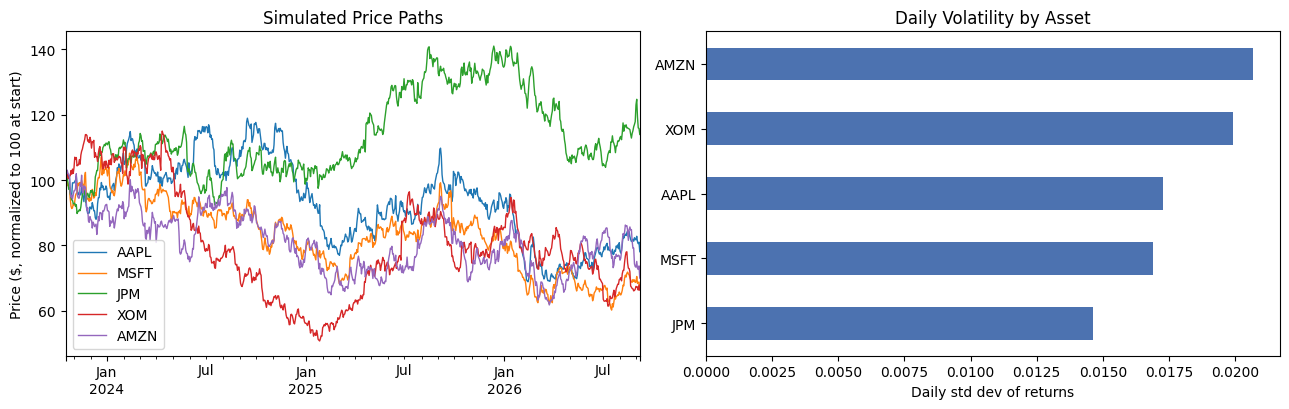

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
prices.plot(ax=axes[0], linewidth=1)
axes[0].set_title("Simulated Price Paths")
axes[0].set_ylabel("Price ($, normalized to 100 at start)")

returns.std().sort_values().plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("Daily Volatility by Asset")
axes[1].set_xlabel("Daily std dev of returns")
plt.tight_layout()
plt.show()

## 2. VaR & Expected Shortfall — Three Methodologies

- **Historical Simulation** — quantile of realized P&L. No distributional assumption.
- **Parametric (Variance-Covariance)** — assumes Normal returns; fast, closed-form, standard for linear portfolios, but understates fat tails.
- **Monte Carlo** — simulates many correlated paths from a fitted Student-t distribution (fat tails), then takes the quantile of simulated P&L.

**Expected Shortfall (ES/CVaR)** — the average loss *beyond* the VaR threshold 

In [5]:
def historical_var_es(pnl_series, confidence):
    alpha = 1 - confidence
    var = -np.quantile(pnl_series, alpha)
    tail_losses = pnl_series[pnl_series <= -var]
    es = -tail_losses.mean() if len(tail_losses) > 0 else var
    return {"VaR": var, "ES": es, "method": "Historical Simulation"}

def parametric_var_es(returns_df, confidence, horizon_days=1):
    cov_daily = returns_df[TICKERS].cov().values
    port_var_daily = WEIGHT_VEC @ cov_daily @ WEIGHT_VEC.T
    port_vol_daily = np.sqrt(port_var_daily)
    port_vol_horizon = port_vol_daily * np.sqrt(horizon_days)

    z = stats.norm.ppf(confidence)
    var_dollar = z * port_vol_horizon * PORTFOLIO_VALUE

    phi_z = stats.norm.pdf(z)
    es_dollar = (phi_z / (1 - confidence)) * port_vol_horizon * PORTFOLIO_VALUE
    return {"VaR": var_dollar, "ES": es_dollar, "method": "Parametric (Variance-Covariance)"}

def monte_carlo_var_es(returns_df, confidence, n_sims=MC_SIMULATIONS, t_dof=T_DOF, seed=123):
    rng = np.random.default_rng(seed)
    mean_daily = returns_df[TICKERS].mean().values
    cov_daily = returns_df[TICKERS].cov().values
    L = np.linalg.cholesky(cov_daily)

    raw_t = rng.standard_t(df=t_dof, size=(n_sims, len(TICKERS)))
    t_scale_correction = np.sqrt((t_dof - 2) / t_dof)
    sim_returns = mean_daily + (raw_t * t_scale_correction) @ L.T
    sim_pnl = (sim_returns @ WEIGHT_VEC) * PORTFOLIO_VALUE

    alpha = 1 - confidence
    var = -np.quantile(sim_pnl, alpha)
    tail_losses = sim_pnl[sim_pnl <= -var]
    es = -tail_losses.mean() if len(tail_losses) > 0 else var
    return {"VaR": var, "ES": es, "method": "Monte Carlo (Student-t)"}

rows = []
for conf in CONFIDENCE_LEVELS:
    for result in (historical_var_es(pnl, conf), parametric_var_es(returns, conf), monte_carlo_var_es(returns, conf)):
        rows.append({
            "Confidence": f"{int(conf*100)}%", "Method": result["method"],
            "VaR ($)": round(result["VaR"], 0), "ES ($)": round(result["ES"], 0),
            "VaR (% notional)": round(result["VaR"] / PORTFOLIO_VALUE * 100, 2),
        })
var_table = pd.DataFrame(rows)
var_table

,Confidence,Method,VaR ($),ES ($),VaR (% notional)
0,95%,Historical Simulation,"217,640.00","285,489.00",2.18
1,95%,Parametric (Variance-Covariance),"202,515.00","253,962.00",2.03
2,95%,Monte Carlo (Student-t),"196,667.00","267,079.00",1.97
3,99%,Historical Simulation,"300,297.00","400,282.00",3.00
4,99%,Parametric (Variance-Covariance),"286,421.00","328,142.00",2.86
5,99%,Monte Carlo (Student-t),"307,454.00","383,327.00",3.07


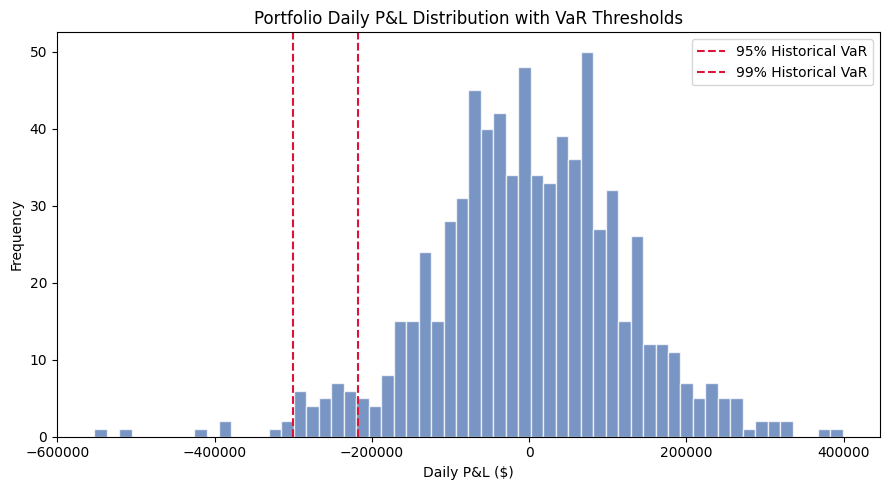

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(pnl, bins=60, color="#4C72B0", alpha=0.75, edgecolor="white")
for _, row in var_table[var_table["Method"] == "Historical Simulation"].iterrows():
    ax.axvline(-row["VaR ($)"], color="crimson", linestyle="--", label=f"{row['Confidence']} Historical VaR")
ax.set_title("Portfolio Daily P&L Distribution with VaR Thresholds")
ax.set_xlabel("Daily P&L ($)")
ax.set_ylabel("Frequency")
ax.legend()
plt.tight_layout()
plt.show()

Parametric VaR understates risk due to normal distribution assumption. Monte Carlo (Student-t) and Historical Simulation track more closely since both capture fat tails. But I think Monte Carlo has an advantage on simulating a path that never might have been observed.

## 3. Backtesting — VaR Model

1. Computes VaR on a **rolling** basis using only prior data (no lookahead) and compares each forecast to that day's realized P&L.
2. Runs the **Kupiec Proportion-of-Failures test** — does the observed breach *rate* match the expected rate (~1% of days for 99% VaR)?
4. Classifies the model under the **Basel traffic-light framework** (Green/Yellow/Red) simple exceptions in the trailing 250 days

In [7]:
def rolling_historical_var(pnl_series, confidence, window):
    results = []
    dates = pnl_series.index
    for i in range(window, len(pnl_series)):
        train_pnl = pnl_series.iloc[i - window:i]
        var_est = historical_var_es(train_pnl, confidence)["VaR"]
        realized = pnl_series.iloc[i]
        results.append({"date": dates[i], "VaR_forecast": var_est,
                         "realized_pnl": realized, "breach": realized < -var_est})
    return pd.DataFrame(results).set_index("date")

bt = rolling_historical_var(pnl, confidence=0.99, window=BACKTEST_WINDOW)
n_obs, n_exceptions = len(bt), int(bt["breach"].sum())
print(f"Backtested {n_obs} days out-of-sample, {n_exceptions} exceptions (breaches)")

Backtested 505 days out-of-sample, 6 exceptions (breaches)


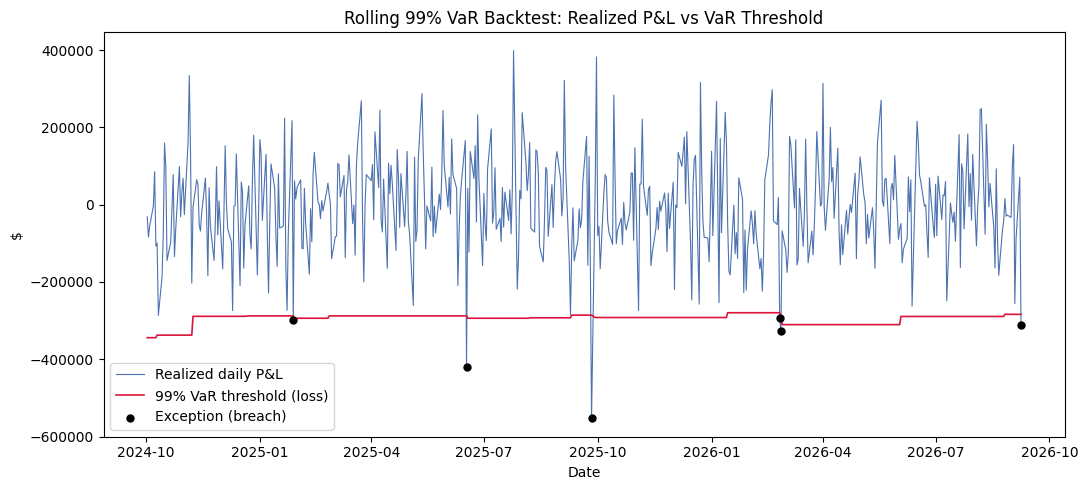

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(bt.index, bt["realized_pnl"], color="#4C72B0", linewidth=0.8, label="Realized daily P&L")
ax.plot(bt.index, -bt["VaR_forecast"], color="crimson", linewidth=1.2, label="99% VaR threshold (loss)")
breaches = bt[bt["breach"]]
ax.scatter(breaches.index, breaches["realized_pnl"], color="black", zorder=5, s=25, label="Exception (breach)")
ax.set_title("Rolling 99% VaR Backtest: Realized P&L vs VaR Threshold")
ax.set_xlabel("Date")
ax.set_ylabel("$")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
def kupiec_pof_test(n_obs, n_exceptions, confidence):
    p_expected = 1 - confidence
    p_observed = n_exceptions / n_obs if n_obs > 0 else 0.0
    if n_exceptions == 0:
        log_l_null = n_obs * np.log(1 - p_expected)
        log_l_alt = n_obs * np.log(1 - p_observed) if p_observed < 1 else 0
    else:
        log_l_null = (n_obs - n_exceptions) * np.log(1 - p_expected) + n_exceptions * np.log(p_expected)
        log_l_alt = (n_obs - n_exceptions) * np.log(1 - p_observed) + n_exceptions * np.log(p_observed)
    lr_stat = -2 * (log_l_null - log_l_alt)
    p_value = 1 - stats.chi2.cdf(lr_stat, df=1)
    return {"n_obs": n_obs, "n_exceptions": n_exceptions,
            "expected_exceptions": round(p_expected * n_obs, 1),
            "observed_rate": round(p_observed, 4), "expected_rate": round(p_expected, 4),
            "LR_statistic": round(lr_stat, 3), "p_value": round(p_value, 4),
            "reject_H0_at_5pct": p_value < 0.05}

def basel_traffic_light(n_exceptions, n_obs=250):
    if n_exceptions <= 4: zone = "Green"
    elif n_exceptions <= 9: zone = "Yellow"
    else: zone = "Red"
    return {"n_exceptions": n_exceptions, "window": n_obs, "zone": zone}

kupiec = kupiec_pof_test(n_obs, n_exceptions, confidence=0.99)
print("Kupiec Proportion-of-Failures test:")
for k, v in kupiec.items():
    print(f"  {k}: {v}")

recent = bt.tail(250)
traffic = basel_traffic_light(int(recent["breach"].sum()), n_obs=len(recent))
print("\\nBasel traffic-light classification (trailing 250 days):")
for k, v in traffic.items():
    print(f"  {k}: {v}")

Kupiec Proportion-of-Failures test:
  n_obs: 505
  n_exceptions: 6
  expected_exceptions: 5.1
  observed_rate: 0.0119
  expected_rate: 0.01
  LR_statistic: 0.17
  p_value: 0.6799
  reject_H0_at_5pct: False
\nBasel traffic-light classification (trailing 250 days):
  n_exceptions: 4
  window: 250
  zone: Green


Interpretation:`reject_H0_at_5pct: False` means we *cannot* reject the hypothesis that the model's breach rate matches the expected 1% — the model looks well-calibrated

## 4. Stress Testing — VaR

1. **Scenario shocks** — apply a defined instantaneous % move per asset.
2. **Correlation breakdown** — in real crises, correlations often spike toward 1 ("all correlations go to 1 in a crisis"). This re-runs Parametric VaR under a stressed, higher-correlation matrix to show how much diversification benefit — and therefore how much VaR itself understates risk — depends on correlations staying at historical levels.

In [11]:
def apply_scenario_shocks():
    rows = []
    for name, shocks in STRESS_SCENARIOS.items():
        pnl_shock = sum(WEIGHTS[t] * PORTFOLIO_VALUE * shocks.get(t, 0.0) for t in TICKERS)
        rows.append({"Scenario": name, "Portfolio P&L ($)": round(pnl_shock, 0),
                      "Portfolio P&L (%)": round(pnl_shock / PORTFOLIO_VALUE * 100, 2)})
    return pd.DataFrame(rows).sort_values("Portfolio P&L ($)")

def correlation_breakdown_var(returns_df, confidence, stressed_corr=0.90):
    vols = returns_df[TICKERS].std().values
    n = len(TICKERS)
    stressed_corr_matrix = np.full((n, n), stressed_corr)
    np.fill_diagonal(stressed_corr_matrix, 1.0)
    stressed_cov = np.outer(vols, vols) * stressed_corr_matrix
    port_vol = np.sqrt(WEIGHT_VEC @ stressed_cov @ WEIGHT_VEC.T)
    z = stats.norm.ppf(confidence)
    return {"stressed_correlation": stressed_corr,
            "VaR_under_stressed_corr": round(z * port_vol * PORTFOLIO_VALUE, 0)}

scenario_results = apply_scenario_shocks()
scenario_results

,Scenario,Portfolio P&L ($),Portfolio P&L (%)
0,2008_style_crisis,"-2,155,000.00",-21.55
1,2020_covid_crash,"-1,700,000.00",-17.00
2,rate_shock_up_100bps,"-370,000.00",-3.70


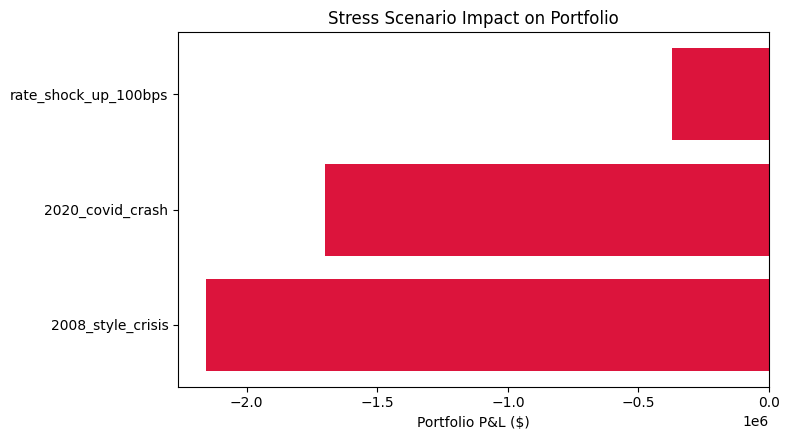

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["crimson" if v < 0 else "seagreen" for v in scenario_results["Portfolio P&L ($)"]]
ax.barh(scenario_results["Scenario"], scenario_results["Portfolio P&L ($)"], color=colors)
ax.set_title("Stress Scenario Impact on Portfolio")
ax.set_xlabel("Portfolio P&L ($)")
plt.tight_layout()
plt.show()

In [13]:
corr_stress = correlation_breakdown_var(returns, confidence=0.99, stressed_corr=0.90)
baseline_99 = var_table[(var_table["Confidence"] == "99%") & (var_table["Method"] == "Parametric (Variance-Covariance)")]["VaR ($)"].values[0]

print(f"Baseline 99% Parametric VaR:      ${baseline_99:,.0f}")
print(f"VaR under stressed correlation:   ${corr_stress['VaR_under_stressed_corr']:,.0f}")
pct_increase = (corr_stress['VaR_under_stressed_corr'] / baseline_99 - 1) * 100
print(f"Increase from diversification breakdown: {pct_increase:.1f}%")

Baseline 99% Parametric VaR:      $286,421
VaR under stressed correlation:   $391,863
Increase from diversification breakdown: 36.8%


## 5. Project Takeaways

- **Parametric VaR consistently understates tail risk** relative to Historical/Monte Carlo — the Normal-distribution assumption doesn't capture fat tails.
- **The model passes Kupiec backtesting** at 99% confidence — breach rate is statistically consistent with the model's stated confidence level.
- **Stress scenarios show losses far in excess of even 99% VaR** — So in such scenarios models should adapt to conditions and be dynamic to avoid understating actual risk
- **Correlation breakdown alone increases VaR by ~35%+** without any change in individual asset volatility.

### Dynamic VAR extensions
- GARCH(1,1) conditional volatility instead of constant historical covariance, so VaR reacts faster to change.
- Marginal VaR / Component VaR to decompose portfolio VaR by position
- Incremental VaR for evaluating a prospective new trade before execution